# 01 – EDA: Telco Churn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_csv('../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [3]:
df.shape

(7043, 21)

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df.sum()

customerID          7590-VHVEG5575-GNVDE3668-QPYBK7795-CFOCW9237-H...
gender              FemaleMaleMaleMaleFemaleFemaleMaleFemaleFemale...
SeniorCitizen                                                    1142
Partner             YesNoNoNoNoNoNoNoYesNoYesNoYesNoNoYesNoNoYesNo...
Dependents          NoNoNoNoNoNoYesNoNoYesYesNoNoNoNoYesNoYesYesNo...
tenure                                                         227990
PhoneService        NoYesYesNoYesYesYesNoYesYesYesYesYesYesYesYesY...
MultipleLines       No phone serviceNoNoNo phone serviceNoYesYesNo...
InternetService     DSLDSLDSLDSLFiber opticFiber opticFiber opticD...
OnlineSecurity      NoYesYesYesNoNoNoYesNoYesYesNo internet servic...
OnlineBackup        YesNoYesNoNoNoYesNoNoYesNoNo internet serviceN...
DeviceProtection    NoYesNoYesNoYesNoNoYesNoNoNo internet serviceY...
TechSupport         NoNoNoYesNoNoNoNoYesNoNoNo internet serviceNoN...
StreamingTV         NoNoNoNoNoYesYesNoYesNoNoNo internet serviceYe...
StreamingMovies     

In [9]:
total_numeric = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [10]:
total_numeric.isna().sum()

np.int64(11)

In [11]:
mask = total_numeric.isna()

In [12]:
df.loc[mask, ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [13]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)

In [14]:
df['TotalCharges'].dtype

dtype('float64')

In [15]:
df['TotalCharges'].isna().sum()

np.int64(0)

In [16]:
df.loc[mask, ['customerID', 'tenure', 'TotalCharges']]

,customerID,tenure,TotalCharges
488,4472-LVYGI,0,0.0
753,3115-CZMZD,0,0.0
936,5709-LVOEQ,0,0.0
1082,4367-NUYAO,0,0.0
1340,1371-DWPAZ,0,0.0
3331,7644-OMVMY,0,0.0
3826,3213-VVOLG,0,0.0
4380,2520-SGTTA,0,0.0
5218,2923-ARZLG,0,0.0
6670,4075-WKNIU,0,0.0


### Fixing `TotalCharges`

**Problem:** `TotalCharges` was stored as text (`object`) instead of a number. `isna()` showed 0 missing values, but converting the column with `pd.to_numeric(errors='coerce')` exposed **11 rows** whose value was a blank space (`" "`).

**Why it was missing:** all 11 customers have `tenure = 0`. They are brand-new customers who haven't been billed yet, so their true total charges are **0**.

**Decision: fill with 0.**
- Not the median: that would invent charges (~₹1,400) for customers who have paid nothing.
- Not dropping: these rows share a pattern (they're all brand-new customers), so dropping them would remove that group from the data, and new customers will keep appearing once the model is in use.

**Lesson:** missing values don't always look like `NaN`. Find out *why* a value is missing before deciding how to fill it.

In [17]:
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

In [18]:
df['SeniorCitizen'].value_counts()

SeniorCitizen
No     5901
Yes    1142
Name: count, dtype: int64

In [19]:
df['churn'] = (df['Churn'] == 'Yes').astype(int)

In [20]:
df['churn'].mean()

np.float64(0.2653698707936959)

In [21]:
from sklearn.model_selection import train_test_split

In [22]:
train_df, test_df = train_test_split (
    df, 
    test_size = 0.2,
    stratify = df['churn'],
    random_state = 42
)

In [23]:
print(train_df.shape, train_df['churn'].mean())
print(test_df.shape, test_df['churn'].mean())

(5634, 22) 0.2653532126375577
(1409, 22) 0.2654364797728886


In [24]:
train_df.to_csv('../data/processed/train.csv', index=False)
test_df.to_csv('../data/processed/test.csv', index=False)

### Train/test split done

From here on, **all EDA uses `train_df` only.**
`test_df` is **locked away until final evaluation**, so that it can give an honest estimate of how the model will perform on new customers.

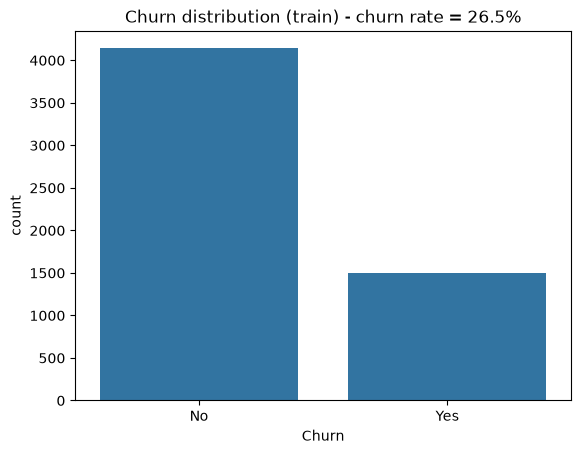

In [25]:
sns.countplot(data=train_df,x='Churn')
plt.title(f"Churn distribution (train) - churn rate = {train_df['churn'].mean():.1%}")
plt.savefig('../reports/figures/target_distribution.png', dpi=120, bbox_inches='tight')
plt.show()

### Why accuracy is misleading here

**Accuracy** = correct predictions ÷ all predictions

We know that **26.5%** of customers churn, so **73.5%** don't.
A "model" that always predicts **"No churn"** is correct for every non-churner, so it gets **73.5% accuracy** without learning anything.

This is useless to the customer success team. They need to know **which customers** will churn, not how many, so they can offer those customers a discount. This model flags **zero** customers, so it catches **zero churners** (recall = 0%).

**Takeaway:** on imbalanced data, accuracy alone is misleading. We'll judge models on **recall, precision and ROC-AUC**, and any real model must clearly beat this 73.5% baseline.

#### Recall: the metric that exposes this
**Recall** = churners the model caught ÷ all actual churners

*"Of all the customers who actually churned, what fraction did we find?"*

The training set has about **1,495 churners**. The "always No" model flags none of them:

> Recall = 0 ÷ 1,495 = **0%**

- **Accuracy** asks: *how often is the model right, across everyone?* It gets credit for the non-churners.
- **Recall** asks: *how many of the customers we care about did we find?* Non-churners don't count.

Its partner, **precision** = churners caught ÷ all customers flagged, measures false alarms (wasted discounts).

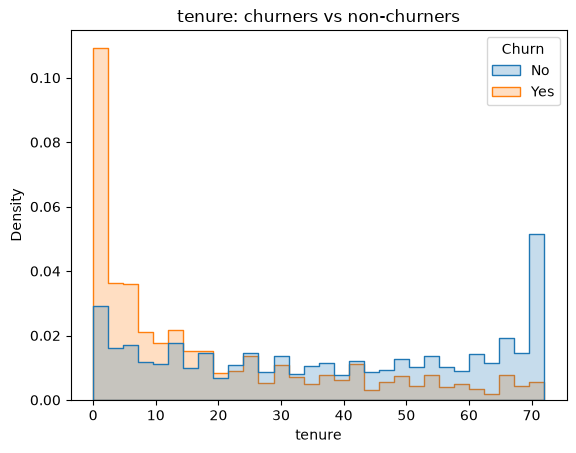

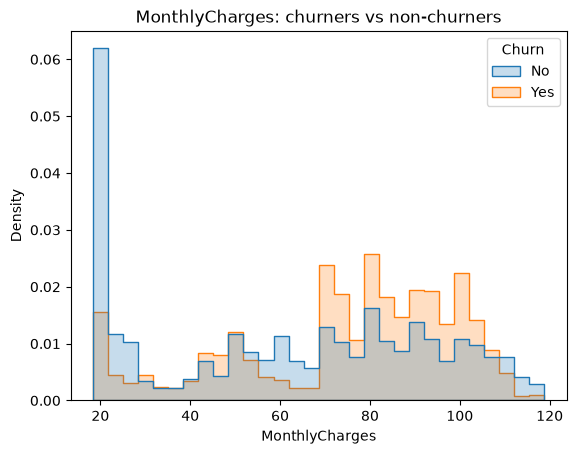

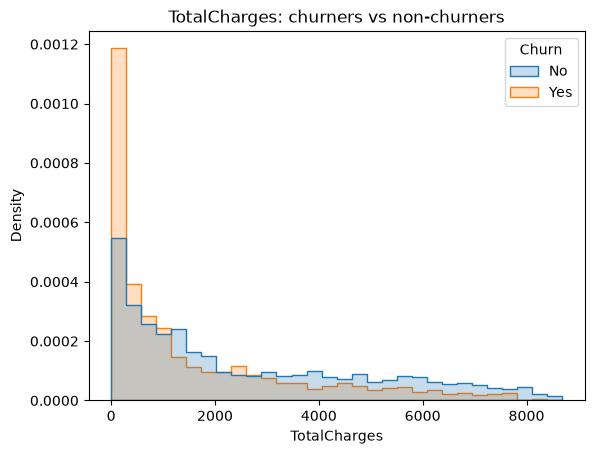

In [26]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

for col in num_cols:
    sns.histplot(data=train_df, x=col, hue='Churn',
                 stat='density', common_norm=False, bins=30, element='step')
    plt.title(f'{col}: churners vs non-churners')
    plt.show()

In [27]:
train_df.groupby('Churn')[['tenure', 'MonthlyCharges', 'TotalCharges']].median()

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.40,1686.15
Yes,10.0,79.95,740.30


### Q4: Numeric features vs churn

**Tenure:** churners are concentrated in the **first few months**. Non-churners are spread out, with a spike at the maximum (72 months).
→ The **early months are the danger zone**: retention efforts should focus on new customers.
*(Careful: this is correlation, not causation. Long-tenure customers have, by definition, already survived many months.)*

**MonthlyCharges:** non-churners spike at ~$20 (mostly phone-only customers with no internet). In the ~$70–$105 range, churners are more common.
→ **Churners tend to pay more per month.** Hypothesis: expensive plans (e.g. fiber optic) are linked to churn. To be tested in step 1.9.

**TotalCharges:** roughly `tenure × MonthlyCharges` (e.g. $50/month × 10 months = $500).
→ That's why its shape looks like tenure's, and why churners have **lower** total charges despite **higher** monthly charges: they leave early.
→ It's largely **redundant** with the other two columns (to be checked in step 1.10).

In [28]:
train_df.groupby('Contract')['churn'].agg(['count', 'mean'])

,count,mean
Contract,,
Month-to-month,3102,0.427466
One year,1173,0.110827
Two year,1359,0.028698


In [29]:
def churn_table(data, col):
    """Return count and churn rate per category of col, highest churn rate first."""
    result = data.groupby(col)['churn'].agg(['count', 'mean'])           # the groupby line, using data and col instead of train_df and 'Contract'
    result = result.sort_values(by='mean', ascending=False)           # sort by the 'mean' column, highest first
    return result

In [30]:
churn_table(train_df, 'Contract')

,count,mean
Contract,,
Month-to-month,3102,0.427466
One year,1173,0.110827
Two year,1359,0.028698


In [46]:
cat_cols = train_df.select_dtypes(include=['object', 'string']).columns.tolist()
cat_cols

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'Churn']

In [32]:
cat_cols.remove('customerID')
cat_cols.remove('Churn')

In [33]:
len(cat_cols)

16

In [34]:
for col in cat_cols:
    print(f'\n=== {col} ===')
    print(churn_table(train_df, col))


=== gender ===
        count      mean
gender                 
Female   2801  0.266333
Male     2833  0.264384

=== SeniorCitizen ===
               count      mean
SeniorCitizen                 
Yes              920  0.410870
No              4714  0.236954

=== Partner ===
         count      mean
Partner                 
No        2905  0.327711
Yes       2729  0.198974

=== Dependents ===
            count      mean
Dependents                 
No           3955  0.313527
Yes          1679  0.151876

=== PhoneService ===
              count      mean
PhoneService                 
Yes            5075  0.267980
No              559  0.241503

=== MultipleLines ===
                  count      mean
MultipleLines                    
Yes                2390  0.287866
No                 2685  0.250279
No phone service    559  0.241503

=== InternetService ===
                 count      mean
InternetService                 
Fiber optic       2483  0.420862
DSL               1937  0.186887


In [35]:
train_df.groupby('InternetService')['MonthlyCharges'].median()

InternetService
DSL            56.15
Fiber optic    92.45
No             20.15
Name: MonthlyCharges, dtype: float64

### Q5: Categorical features vs churn
*(Overall churn rate: 26.5%. A feature is predictive if its categories' churn rates differ a lot.)*

**Strongest signals:**
- **Contract:** month-to-month 42.7% vs two-year 2.9%. Customers on long contracts rarely leave.
- **PaymentMethod:** electronic check 45.7% vs automatic credit card 14.9%. Automatic payers may be more committed *(association, not causation)*.
- **InternetService:** fiber optic 42.1% vs DSL 18.7% vs none 7.2%. Fiber is also the most expensive plan (median $92 vs $56 vs $20), which supports the Q4 finding that higher payers churn more.
- **TechSupport / OnlineSecurity:** customers *without* these add-ons churn at ~42% vs ~15% with them.

**Weak or useless:**
- **gender:** 26.6% vs 26.4%. No signal.
- **PhoneService, MultipleLines:** small gaps (2–4 points). Weak.
- **StreamingTV / StreamingMovies:** Yes vs No differ by only ~3 points.

**Redundancy found:** "No internet service" in 6 add-on columns is the same 1,214 customers as `InternetService = No`. **Phase 2 decision:** recode it to "No" in those columns, to avoid 7 duplicate columns after one-hot encoding.

**Excluded from analysis:** `customerID` (unique per customer, so no pattern to learn and a risk of memorisation), `Churn` (the target; using it as a feature would be target leakage).

In [36]:
contract_table = churn_table(train_df, 'Contract')
contract_table

,count,mean
Contract,,
Month-to-month,3102,0.427466
One year,1173,0.110827
Two year,1359,0.028698


In [37]:
contract_table = contract_table.reset_index()
contract_table

,Contract,count,mean
0,Month-to-month,3102,0.427466
1,One year,1173,0.110827
2,Two year,1359,0.028698


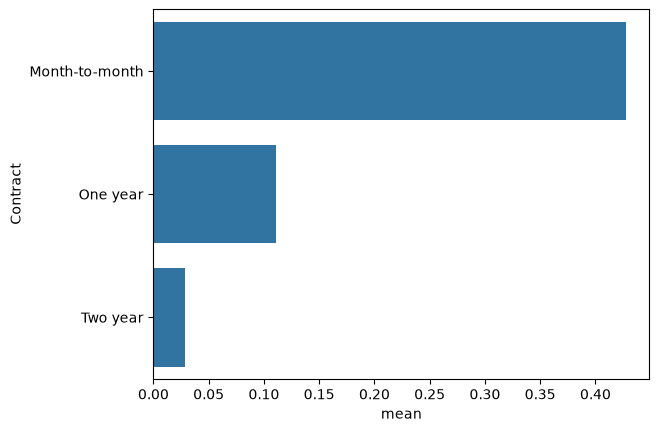

In [38]:
sns.barplot(data=contract_table, x='mean', y='Contract')
plt.show()

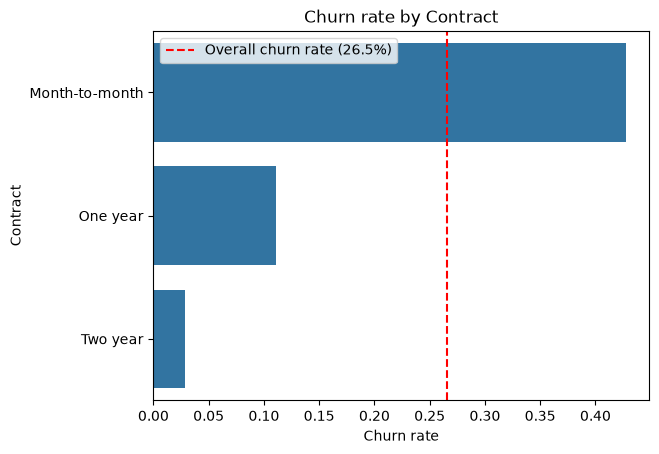

In [39]:
overall = train_df['churn'].mean()

sns.barplot(data=contract_table, x='mean', y='Contract')
plt.axvline(overall, color='red', linestyle='--', label=f'Overall churn rate ({overall:.1%})')
plt.xlabel('Churn rate')
plt.title('Churn rate by Contract')
plt.legend()
plt.show()

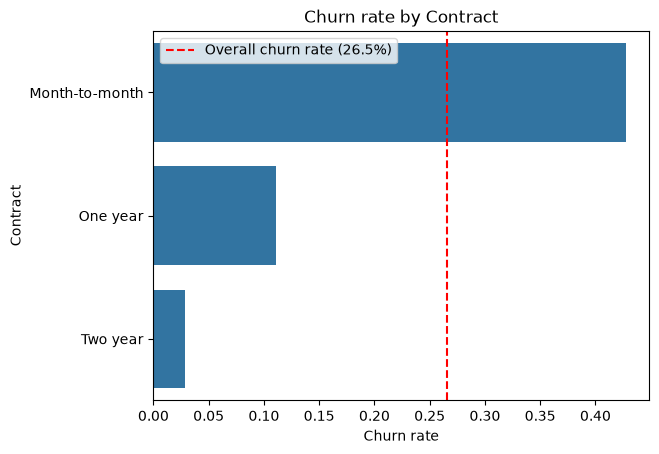

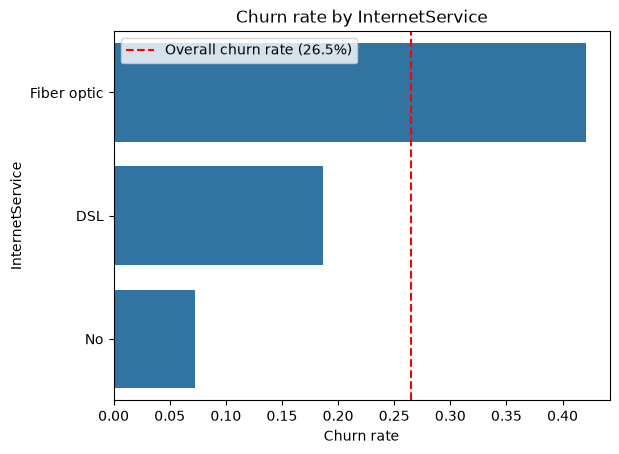

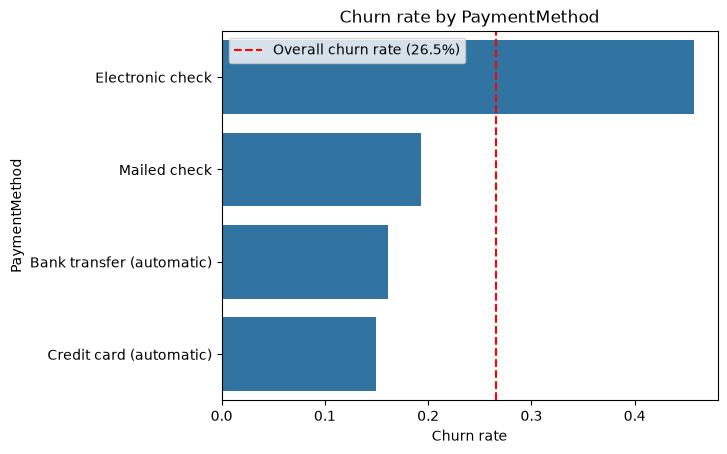

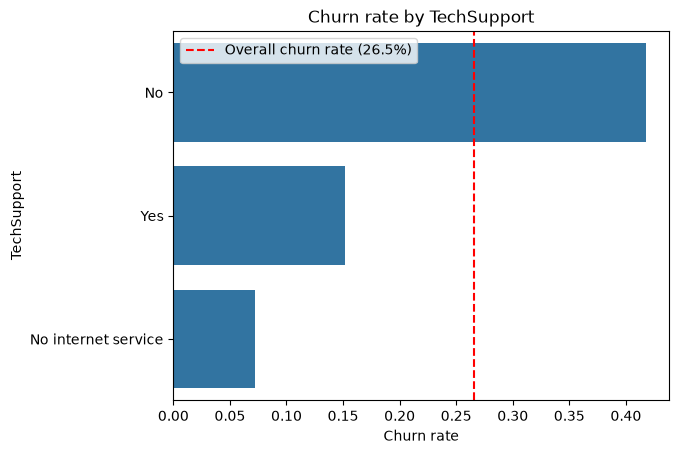

In [40]:
top_features = ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport']

for col in top_features:
    table = churn_table(train_df, col).reset_index()

    sns.barplot(data=table, x='mean', y=col)
    plt.axvline(overall, color='red', linestyle='--', label=f'Overall churn rate ({overall:.1%})')
    plt.xlabel('Churn rate')
    plt.title(f'Churn rate by {col}')
    plt.legend()
    plt.savefig(f'../reports/figures/churn_rate_{col}.png', dpi=120, bbox_inches='tight')
    plt.show()

In [41]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'churn']
corr = train_df[num_cols].corr()
corr

,tenure,MonthlyCharges,TotalCharges,churn
tenure,1.000000,0.256700,0.829698,-0.345593
MonthlyCharges,0.256700,1.000000,0.654117,0.198040
TotalCharges,0.829698,0.654117,1.000000,-0.193761
churn,-0.345593,0.198040,-0.193761,1.000000


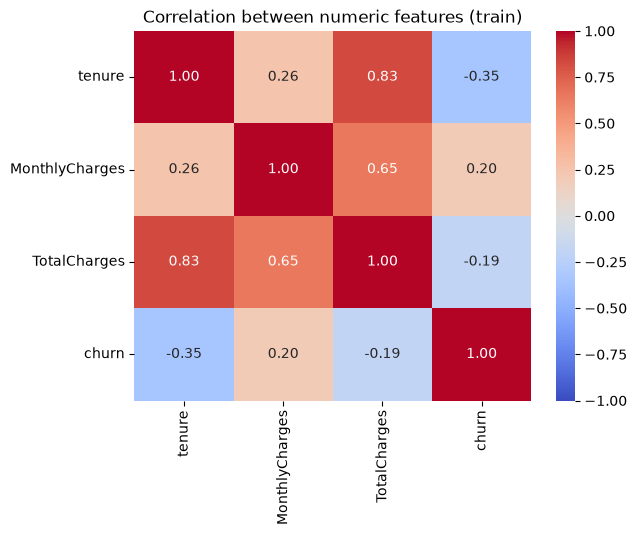

In [42]:
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between numeric features (train)')
plt.savefig('../reports/figures/correlation_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

In [43]:
estimated_total = train_df['tenure'] * train_df['MonthlyCharges']
estimated_total.head()

3738    1722.00
3151    1126.50
4860     527.15
3867    1911.00
3810      44.55
dtype: float64

In [44]:
estimated_total.corr(train_df['TotalCharges'])

np.float64(0.9995620682846215)

### Q6: Is `TotalCharges` redundant?

**Test:** `corr(tenure × MonthlyCharges, TotalCharges)` ≈ **0.99**

**1. What it tells us:** `TotalCharges` is almost entirely `tenure × MonthlyCharges`: how long the customer has stayed, multiplied by what they pay each month.

**2. Why it isn't exactly 1:** `MonthlyCharges` is the customer's **current** price, but `TotalCharges` is the sum of **everything they've paid so far**. If a customer changed plans (e.g. $35/month for 5 months, then upgraded in month 6), or had price increases or discounts, current price × tenure won't exactly match their real total.

**3. Should we drop it?**
- **For dropping:** we already have its two components. `tenure` and `MonthlyCharges` separately tell us more (how long they've stayed, and how expensive their plan is) than their combined total.
- **Against dropping:**
  - The small gap between `TotalCharges` and `tenure × MonthlyCharges` shows whether a customer's **price changed** over time, which could itself be linked to churn.
  - Linear models like logistic regression can't multiply features on their own, so `TotalCharges` gives them that combination ready-made. (Tree-based models can approximate it themselves.)

**Decision:** this is an empirical question. In **Phase 3**, we'll train models **with and without** `TotalCharges` and let the scores decide.

## Summary of EDA findings

### Key findings
1. **Imbalanced target:** only **26.5%** of customers churn, so an "always No" model gets **73.5% accuracy** but catches **0 churners**. → We'll judge models on recall, precision and ROC-AUC, not accuracy.
2. **Contract is the strongest signal:** month-to-month customers churn at **42.7%** vs **2.9%** for two-year contracts (**~15×** as likely).
3. **New customers are the risk:** churners are concentrated in the first few months of tenure (correlation with churn ≈ **−0.35**).
4. **Higher payers churn more:** fiber optic customers pay the most (median **$92.45**/month) and churn at **42.1%**, vs **7.2%** for customers with no internet.
5. **Payment & support:** electronic check users churn at **45.7%**; customers without tech support churn at **41.8%** vs **15.2%** with it.

### Hypotheses for the model (to test in Phase 3)
- **Contract, tenure and InternetService** will be among the model's most important features.
- **Gender** will contribute almost nothing.
- Removing **TotalCharges** won't noticeably hurt performance, since it's ~99% explained by tenure × MonthlyCharges.

### Decisions carried into Phase 2
- Drop `customerID` from the features (keep it as an identifier to attach predictions to).
- Separate `churn` as the target (**y**); neither `Churn` nor `churn` can be a feature.
- Recode "No internet service" → "No" in the 6 add-on columns (it duplicates `InternetService = No`).
- Train models **with and without** `TotalCharges` and compare.
- `test_df` stays untouched until final evaluation.